# EV Battery Health Prediction: Step 5, Predicting Remaining Useful Life (RUL)

So far I predicted the battery's **current health** (SOH). In this notebook I go one step further and predict its **future**: how many more discharge cycles are left before the battery reaches the end-of-life threshold. This is called **Remaining Useful Life (RUL)**.

| Step | What I do |
|---|---|
| 1 | Load the NASA data for one battery, calculate SOH, plot the capacity fade |
| 2 | Combine 4 batteries and explore the data |
| 3 | Train models to predict SOH |
| 4 | Explain the model with SHAP |
| **5 (this notebook)** | **Predict Remaining Useful Life (RUL)** |
| 6 | Build and deploy a Streamlit app |

## 1. SOH vs RUL

| | SOH | RUL |
|---|---|---|
| Question | How healthy is the battery **now**? | How many cycles **until it wears out**? |
| Unit | Percent | Number of discharge cycles |
| Useful for | Health status | Maintenance planning, warranty, replacement decisions |

RUL is harder than SOH. SOH describes the present state, which the measurements directly reflect. RUL has to look ahead, so the model needs to pick up how fast the battery is degrading.

## 2. Importing libraries

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

## 3. Loading the data

In [11]:
df = pd.read_csv("all_batteries.csv")
df = df.sort_values(["battery", "cycle"]).reset_index(drop=True)

print("Shape:", df.shape)
df.head()

Shape: (636, 10)


,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s,soh_percent,battery
0,1,1.856487,3.529829,2.612467,-1.818702,32.572328,38.982181,3690.234,100.000000,B0005
1,2,1.846327,3.537320,2.587209,-1.817560,32.725235,39.033398,3672.344,99.452721,B0005
2,3,1.835349,3.543737,2.651917,-1.816487,32.642862,38.818797,3651.641,98.861386,B0005
3,4,1.835263,3.543666,2.592948,-1.825589,32.514876,38.762305,3631.563,98.856718,B0005
4,5,1.834646,3.542343,2.547420,-1.826114,32.382349,38.665393,3629.172,98.823482,B0005


## 4. Defining end of life and creating the RUL column

For each battery, I define **end of life (EOL)** as the first discharge cycle where SOH drops to **80% or below**, which is the common EV standard.

Then for every cycle:

`RUL = EOL cycle - current cycle`

So RUL counts down to 0 at the moment the battery reaches EOL. I only keep cycles **up to** EOL, because "remaining life" after the battery is already worn out is not meaningful here.

The 80% threshold is a choice I made. A different threshold (for example 70%) would give different RUL values, so I keep it as a setting at the top of the cell.

In [12]:
EOL_SOH = 80  # end-of-life threshold in SOH %


def add_rul(g):
    """Keep cycles up to the first time SOH <= EOL_SOH and add the RUL column."""
    below = g[g["soh_percent"] <= EOL_SOH]
    if below.empty:
        return None  # this battery never reached end of life

    eol_cycle = below["cycle"].iloc[0]
    g = g[g["cycle"] <= eol_cycle].copy()
    g["rul"] = eol_cycle - g["cycle"]
    return g


frames = []
for name, g in df.groupby("battery"):
    out = add_rul(g)
    if out is None:
        print(f"{name}: never reached {EOL_SOH}% SOH, so it is left out")
    else:
        frames.append(out)

rul_df = pd.concat(frames, ignore_index=True)

summary = rul_df.groupby("battery").agg(
    eol_cycle=("cycle", "max"),
    rows_kept=("cycle", "size"),
)
summary

,eol_cycle,rows_kept
battery,,
B0005,101,101
B0006,61,61
B0007,124,124
B0018,75,75


A note on how EOL is found: SOH does not fall perfectly smoothly (there are small bumps from capacity regeneration, which I saw in Step 1). Using the **first** time SOH reaches the threshold is a simple and consistent rule, but near the threshold a bump can briefly lift SOH back above it.

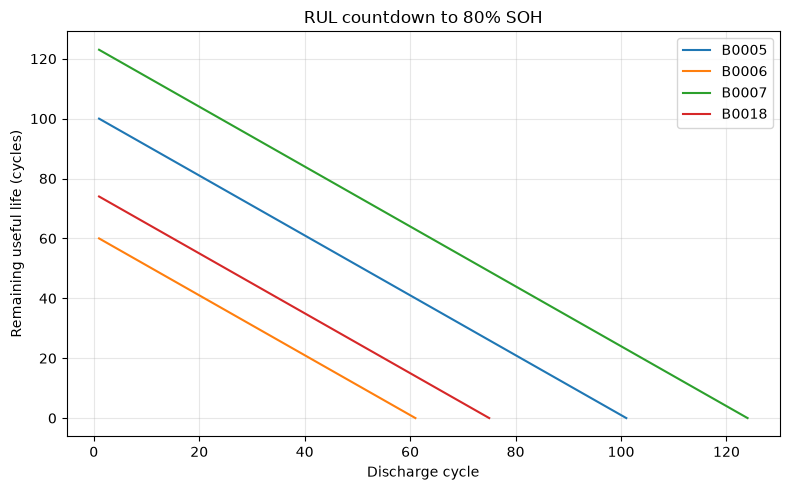

In [13]:
plt.figure(figsize=(8, 5))
for name, g in rul_df.groupby("battery"):
    plt.plot(g["cycle"], g["rul"], label=name)

plt.title(f"RUL countdown to {EOL_SOH}% SOH")
plt.xlabel("Discharge cycle")
plt.ylabel("Remaining useful life (cycles)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Features and the train/test split

I use the same discharge features as before and leave out `cycle`, because a real EV does not always know its exact cycle count. As in Step 3, I **train on B0005, B0006 and B0007** and **test on B0018**, a battery the model has never seen.

In [14]:
TARGET = "rul"
TRAIN_BATTERIES = ["B0005", "B0006", "B0007"]
TEST_BATTERY = "B0018"

FEATURES = [
    "avg_voltage",
    "min_voltage",
    "avg_current",
    "avg_temp",
    "max_temp",
    "discharge_time_s",
]

assert TEST_BATTERY in rul_df["battery"].values, f"{TEST_BATTERY} never reached end of life at {EOL_SOH}% SOH"

train = rul_df[rul_df["battery"].isin(TRAIN_BATTERIES)]
test = rul_df[rul_df["battery"] == TEST_BATTERY]

print(f"Training rows: {len(train)} | Testing rows: {len(test)} ({TEST_BATTERY})")

Training rows: 286 | Testing rows: 75 (B0018)


## 6. Smoothing the features

Single cycles are noisy, especially around the capacity regeneration bumps. RUL is about the **trend** of degradation, so I also tried **smoothed features**: for each cycle, the average of that cycle and the previous 4 cycles, calculated separately for each battery.

The window only looks **backwards**, so it uses information a real system would actually have at that moment. A centred window would peek at future cycles, which would be cheating.

I compare the raw and the smoothed version later.

In [15]:
WINDOW = 5

smooth_cols = [f"{f}_smooth" for f in FEATURES]

rul_df[smooth_cols] = (
    rul_df.groupby("battery")[FEATURES]
    .transform(lambda s: s.rolling(WINDOW, min_periods=1).mean())
)

train = rul_df[rul_df["battery"].isin(TRAIN_BATTERIES)]
test = rul_df[rul_df["battery"] == TEST_BATTERY]

rul_df[["battery", "cycle"] + FEATURES[:2] + smooth_cols[:2]].head(8)

,battery,cycle,avg_voltage,min_voltage,avg_voltage_smooth,min_voltage_smooth
0,B0005,1,3.529829,2.612467,3.529829,2.612467
1,B0005,2,3.537320,2.587209,3.533574,2.599838
2,B0005,3,3.543737,2.651917,3.536962,2.617198
3,B0005,4,3.543666,2.592948,3.538638,2.611135
4,B0005,5,3.542343,2.547420,3.539379,2.598392
5,B0005,6,3.541335,2.520948,3.541680,2.580088
6,B0005,7,3.541025,2.487927,3.542421,2.560232
7,B0005,8,3.554133,2.665205,3.544500,2.562890


## 7. Models

The same three models as in Step 3:

| Model | Why |
|---|---|
| **Linear Regression** | A simple baseline |
| **Random Forest** | Handles non-linear patterns |
| **XGBoost** | Gradient boosting, strong on tabular data |

Metrics are now in **cycles**, which is easy to interpret. For example, an MAE of 8 means the prediction is about 8 cycles off on average.

In [16]:
def get_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
    }


def evaluate(feature_cols, label):
    rows, preds = [], {}
    for name, model in get_models().items():
        model.fit(train[feature_cols], train[TARGET])
        p = model.predict(test[feature_cols])
        preds[name] = p
        rows.append(
            {
                "Features": label,
                "Model": name,
                "MAE (cycles)": mean_absolute_error(test[TARGET], p),
                "RMSE (cycles)": np.sqrt(mean_squared_error(test[TARGET], p)),
                "R2": r2_score(test[TARGET], p),
            }
        )
    return pd.DataFrame(rows), preds


raw_results, raw_preds = evaluate(FEATURES, "Raw")
smooth_results, smooth_preds = evaluate(smooth_cols, "Smoothed")

results = pd.concat([raw_results, smooth_results], ignore_index=True).round(3)
results.to_csv("rul_model_results.csv", index=False)
results

,Features,Model,MAE (cycles),RMSE (cycles),R2
0,Raw,Linear Regression,10.950,15.227,0.505
1,Raw,Random Forest,13.322,17.210,0.368
2,Raw,XGBoost,12.843,15.920,0.459
3,Smoothed,Linear Regression,15.790,19.833,0.161
4,Smoothed,Random Forest,16.100,20.575,0.097
5,Smoothed,XGBoost,16.386,18.844,0.242


## 8. Predicted vs actual RUL

The black line is the true RUL of the unseen battery. It counts down to 0 at end of life. The dashed lines are the model predictions. The closer a line follows the black one, the better.

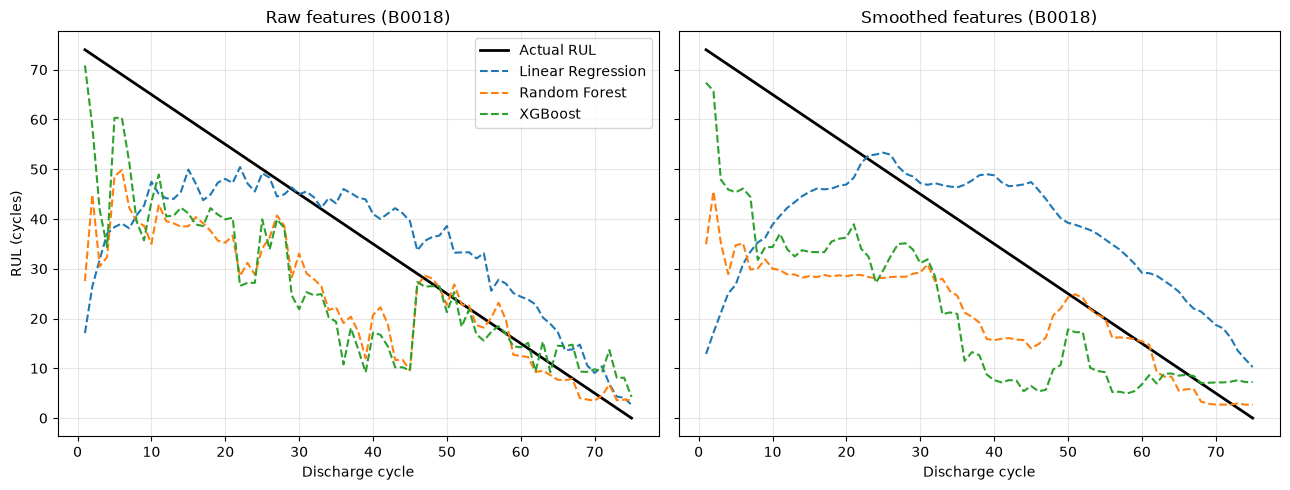

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, preds, title in [
    (axes[0], raw_preds, "Raw features"),
    (axes[1], smooth_preds, "Smoothed features"),
]:
    ax.plot(test["cycle"].values, test[TARGET].values, color="black", linewidth=2, label="Actual RUL")
    for name, p in preds.items():
        ax.plot(test["cycle"].values, p, linestyle="--", label=name)
    ax.set_title(f"{title} ({TEST_BATTERY})")
    ax.set_xlabel("Discharge cycle")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("RUL (cycles)")
axes[0].legend()
plt.tight_layout()
plt.savefig("rul_predicted_vs_actual.png", dpi=150)
plt.show()

## 9. Where is the error largest?

An average error can hide something important. In practice the prediction matters most **close to end of life**, when a decision about replacing the battery is needed. Here I compare the error in the first half of the battery's life with the error in the second half, for the best model by RMSE.

In [18]:
best_row = results.sort_values("RMSE (cycles)").iloc[0]
print(f"Best by RMSE: {best_row['Model']} with {best_row['Features']} features")

best_preds = (smooth_preds if best_row["Features"] == "Smoothed" else raw_preds)[best_row["Model"]]

err = pd.DataFrame(
    {
        "cycle": test["cycle"].values,
        "actual_rul": test[TARGET].values,
        "predicted_rul": best_preds,
    }
)
err["abs_error"] = (err["actual_rul"] - err["predicted_rul"]).abs()

half = len(err) // 2
print()
print(f"MAE, first half of life:  {err['abs_error'].iloc[:half].mean():.2f} cycles")
print(f"MAE, second half of life: {err['abs_error'].iloc[half:].mean():.2f} cycles")

Best by RMSE: Linear Regression with Raw features

MAE, first half of life:  14.11 cycles
MAE, second half of life: 7.87 cycles


## 10. My observations from this run

- **EOL cycle for each battery:** B0005 at cycle 101, B0006 at 61, B0007 at 124 and B0018 at 75. The lifetimes differ a lot, which is hard for a model trained on only three batteries.
- **Best model and feature version (raw or smoothed):** Linear Regression with raw features (the lowest RMSE).
- **Its MAE and RMSE in cycles:** MAE about 10.9 cycles and RMSE about 15.2 cycles (R2 about 0.51) on B0018.
- **Did smoothing help?** No. The smoothed versions were worse for all three models (MAE about 15.8 to 16.4 cycles, compared with 10.9 to 13.3 for raw). The 5-cycle backward window may add lag, so the features react more slowly to the current state of the battery.
- **Is the error larger early or late in life?** Early. For the best model the MAE is about 14.1 cycles in the first half of life and about 7.9 cycles in the second half, which is the better way round for a replacement decision, but RUL is still far less accurate than SOH.
- **Anything surprising:** the simple Linear Regression beat Random Forest and XGBoost on RUL, which is the opposite of the SOH result in Step 3. With only 286 training rows and very different battery lifetimes, the more flexible models probably have little to learn from. Only one test battery is used, so this ranking could change with a different held-out battery.

## 11. Limitations

- **Very little data.** Only three batteries are used for training and one for testing, and each has roughly one to two hundred cycles. RUL results from a setup this small should be treated as a proof of concept, not a reliable forecast.
- **One test battery.** The scores come from a single battery. A fuller check would hold out each battery in turn (leave-one-battery-out).
- **The 80% threshold is my choice.** Changing it changes the RUL values and the scores.
- **Lab conditions.** These are controlled lab cycles with fixed test settings, which is not the same as real driving.
- **Noise near end of life.** The capacity regeneration bumps can shift when a battery appears to cross the threshold, which makes the RUL labels themselves a little noisy.

## 12. Next step

In Step 6 I will build a **Streamlit app** where a user can enter or upload discharge measurements and see the predicted SOH and RUL.